# Séries Históricas e Indicadores Socioeconômicos do Brasil (2016 – 2026)
### Termômetros Macroeconômicos, Mercado de Trabalho, Indústria e Poder de Compra do Cidadão
### Análise Comparativa por Mandatos Presidenciais: Temer, Bolsonaro e Lula

---

> 💡 **Como rodar este Notebook localmente:**
> - Selecione o kernel **`Python (trad_x_municipio)`** no canto superior direito do seu editor (ele já possui todas as bibliotecas necessárias: `pandas`, `matplotlib`, `openpyxl`, `numpy`).

---

## 🎯 Estrutura e Metodologia
* **Recorte Temporal (2016 a 2026):** Todos os gráficos cobrem o período de 2016 a 2026 para permitir a comparação visual imediata entre os três períodos presidenciais:
  * 🏛️ **Governo Temer (2016 – 2018):** Faixa sombreada em **cinza** (`#6C757D`).
  * 🏛️ **Governo Bolsonaro (2019 – 2022):** Faixa sombreada em **amarelo ouro** (`#FFC107`).
  * 🏛️ **Governo Lula (2023 – 2026):** Faixa sombreada em **tom avermelhado suave** (`#DC3545`).
* **Tratamento dos Dados Parciais de 2026:**
  * Indicação explícita de **até qual mês de 2026** os dados oficiais estão apurados (ex: *Até Jun/2026*, *Até Ago/2026*).
  * **Projeção Linear de Fechamento de 2026:** Calculada pela fórmula oficial solicitada: `Projeção Anual = (Valor Acumulado / Meses Decorridos) * 12`.
* **Subdivisão dos Gráficos:**
  1. 🚗 **Mercado Automotivo:** Venda Total de Veículos no Brasil — Novos e Usados (BCB 1374 e FENAUTO) em Milhões de Veículos com Projeção Tracejada.
  2. 🚗 **Venda Mensal de Veículos Novos Zero KM:** Gráfico de barras mensais com rótulos e segmentação por governo (BCB SGS 1374).
  3. 🏠 **Venda de Imóveis Financiados pelo SBPE:** Quantidade oficial de unidades habitacionais (BCB SGS 20703) com projeção tracejada.
  4. 🛍️ **Comércio Varejista:** Faturamento Nominal em R$ Trilhões (BCB SGS 28544) com projeção tracejada.
  5. ✈️ **Gastos de Brasileiros no Exterior:** Despesas internacionais em US$ Bilhões (BCB SGS 22742) com projeção tracejada.
  6. 🌾 **Agronegócio:** Saldo Comercial Líquido das Exportações em US$ Bilhões (AgroStat / MAPA) com projeção tracejada.
  7. 💼 **Trabalho Formal:** Pessoas com Carteira Assinada / CLT (IBGE / PNAD / MTE / BCB SGS 24379).
  8. 🧑‍💼 **Microempreendedor Individual:** Quantidade de MEIs Ativos no Brasil (Receita Federal / Mapa de Empresas).
  9. 🍞 **Poder de Compra — Cesta Básica:** % do Salário Mínimo (DIEESE / BCB SGS 7493).
  10. 🔥 **Poder de Compra — 1 Botijão de Gás (13kg):** % do Salário Mínimo (ANP / BCB SGS 1619).
  11. ⛽ **Poder de Compra — 1 Litro de Gasolina Comum:** % do Salário Mínimo (ANP / BCB SGS 1619).

---


In [1]:
import urllib.request
import json
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

# Configuração de estilo visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#EEEEEE'
plt.rcParams['grid.linestyle'] = '--'

def aplicar_faixas_governos(ax, ylim=None, y_pos_text=None):
    """
    Aplica o padrão visual de governos:
    - 2016 a 2018: Governo Temer (cinza)
    - 2019 a 2022: Governo Bolsonaro (amarelo ouro #FFC107)
    - 2023 a 2026: Governo Lula (sombra avermelhada suave #DC3545)
    """
    ax.axvspan(2015.5, 2018.5, color='#6C757D', alpha=0.15, zorder=0)
    ax.axvspan(2018.5, 2022.5, color='#FFC107', alpha=0.22, zorder=0)
    ax.axvspan(2022.5, 2026.5, color='#DC3545', alpha=0.12, zorder=0)
    
    if ylim is not None:
        ax.set_ylim(ylim)
        
    y_min, y_max = ax.get_ylim()
    y_text = (y_min + (y_max - y_min) * 0.93) if y_pos_text is None else y_pos_text
    
    ax.text(2017.0, y_text, 'Gov. Temer', ha='center', va='center', fontsize=9, 
            fontweight='bold', color='#495057', bbox=dict(boxstyle='round,pad=0.2', facecolor='#E9ECEF', edgecolor='#CED4DA', alpha=0.85))
    ax.text(2020.5, y_text, 'Gov. Bolsonaro', ha='center', va='center', fontsize=9, 
            fontweight='bold', color='#856404', bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3CD', edgecolor='#FFEEBA', alpha=0.92))
    ax.text(2024.5, y_text, 'Gov. Lula', ha='center', va='center', fontsize=9, 
            fontweight='bold', color='#B71C1C', bbox=dict(boxstyle='round,pad=0.2', facecolor='#F8D7DA', edgecolor='#F5C6CB', alpha=0.85))

def aplicar_faixas_governos_datas(ax, ylim=None, y_pos_text=None):
    """
    Aplica as faixas de governos em gráficos com eixo temporal datetime (mês a mês):
    """
    ax.axvspan(pd.to_datetime('2015-12-15'), pd.to_datetime('2018-12-31'), color='#6C757D', alpha=0.15, zorder=0)
    ax.axvspan(pd.to_datetime('2018-12-31'), pd.to_datetime('2022-12-31'), color='#FFC107', alpha=0.22, zorder=0)
    ax.axvspan(pd.to_datetime('2022-12-31'), pd.to_datetime('2026-12-31'), color='#DC3545', alpha=0.12, zorder=0)
    
    if ylim is not None:
        ax.set_ylim(ylim)
        
    y_min, y_max = ax.get_ylim()
    y_text = (y_min + (y_max - y_min) * 0.93) if y_pos_text is None else y_pos_text
    
    ax.text(pd.to_datetime('2017-07-01'), y_text, 'Gov. Temer', ha='center', va='center', fontsize=9, 
            fontweight='bold', color='#495057', bbox=dict(boxstyle='round,pad=0.2', facecolor='#E9ECEF', edgecolor='#CED4DA', alpha=0.85))
    ax.text(pd.to_datetime('2021-01-01'), y_text, 'Gov. Bolsonaro', ha='center', va='center', fontsize=9, 
            fontweight='bold', color='#856404', bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3CD', edgecolor='#FFEEBA', alpha=0.92))
    ax.text(pd.to_datetime('2024-09-01'), y_text, 'Gov. Lula', ha='center', va='center', fontsize=9, 
            fontweight='bold', color='#B71C1C', bbox=dict(boxstyle='round,pad=0.2', facecolor='#F8D7DA', edgecolor='#F5C6CB', alpha=0.85))

print("✅ Bibliotecas importadas e funções visuais de layout configuradas!")


✅ Bibliotecas importadas e funções visuais de layout configuradas!


## 📡 1. Extração via API do Banco Central (SGS) com Metadados de 2026
A função abaixo consulta o SGS do Banco Central, identifica o último mês apurado de 2026 e calcula a projeção de fechamento: `(Total / Meses Decorridos) * 12`.


In [2]:
meses_nomes = {1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun', 
               7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'}

series_mensais = {}

def extrair_serie_com_projecao(codigo_sgs, nome_indicador, ano_inicio=2016, ano_fim=2026, agregacao='soma'):
    """
    Extrai série histórica da API do Banco Central e calcula projeção anual de 2026.
    Armazena a série mensal completa em `series_mensais[nome_indicador]`.
    """
    url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo_sgs}/dados?formato=json"
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'})
    
    for tentativa in range(3):
        try:
            with urllib.request.urlopen(req, timeout=15) as response:
                dados = json.loads(response.read().decode('utf-8'))
                
            df = pd.DataFrame(dados)
            df['data'] = pd.to_datetime(df['data'], format='%d/%m/%Y')
            df['valor'] = pd.to_numeric(df['valor'], errors='coerce')
            df['ano'] = df['data'].dt.year
            df = df[(df['ano'] >= ano_inicio) & (df['ano'] <= ano_fim)].sort_values('data').reset_index(drop=True)
            
            # Guarda a série mensal detalhada
            series_mensais[nome_indicador] = df[['data', 'ano', 'valor']].copy()
            
            # Detecção de meses em 2026
            df_2026 = df[df['ano'] == 2026]
            mes_max = df_2026['data'].dt.month.max() if not df_2026.empty else 12
            qtd_meses = len(df_2026) if not df_2026.empty else 12
            
            if agregacao == 'media':
                df_anual = df.groupby('ano')['valor'].mean().reset_index()
                val_2026 = df_anual.loc[df_anual['ano'] == 2026, 'valor'].values[0] if 2026 in df_anual['ano'].values else 0
                val_proj = val_2026
            else:
                df_anual = df.groupby('ano')['valor'].sum().reset_index()
                val_2026 = df_anual.loc[df_anual['ano'] == 2026, 'valor'].values[0] if 2026 in df_anual['ano'].values else 0
                val_proj = (val_2026 / qtd_meses) * 12 if qtd_meses > 0 and qtd_meses < 12 else val_2026

            # Se o ano de 2026 não possui dados apurados na série, mantém o último valor histórico disponível
            if 2026 not in df_anual['ano'].values and not df.empty:
                ultimo_reg = df.sort_values('data').dropna(subset=['valor']).iloc[-1]
                ultimo_val = ultimo_reg['valor']
                ultimo_mes_num = ultimo_reg['data'].month
                df_anual = pd.concat([df_anual, pd.DataFrame({'ano': [2026], 'valor': [ultimo_val]})], ignore_index=True)
                val_proj = ultimo_val
                mes_txt = meses_nomes.get(ultimo_mes_num, "Jun")
            else:
                mes_txt = meses_nomes.get(mes_max, f"Mês {mes_max}")
                
            df_anual.rename(columns={'valor': nome_indicador}, inplace=True)
            print(f"✔️ [BCB SGS {codigo_sgs}] '{nome_indicador}': 2026 apurado até {mes_txt} ({qtd_meses} meses) | Proj: {val_proj:.2f}")
            return df_anual, mes_txt, val_proj
        except Exception as e:
            if tentativa < 2:
                time.sleep(1.5)
                continue
            raise RuntimeError(f"Erro ao consultar SGS {codigo_sgs}: {e}")

print("🔍 Extraindo indicadores da API do Banco Central com projeções de 2026...")

# 1. Veículos Novos Vendidos (SGS 1374)
df_veic, mes_veic, proj_veic = extrair_serie_com_projecao(1374, 'carros_novos_vendidos', agregacao='soma')

# 2. Venda de Imóveis Financiados PF em R$ Mi (SGS 20704) e Quantidade de Unidades SBPE (SGS 20703)
df_imob, mes_imob, proj_imob = extrair_serie_com_projecao(20704, 'imoveis_vendas_rs_mi', agregacao='soma')
df_imob_u, mes_imob_u, proj_imob_u = extrair_serie_com_projecao(20703, 'imoveis_unidades_sbpe', agregacao='soma')

# 3. Comércio Varejista Ampliado - Faturamento em R$ Mi (SGS 28544)
df_com, mes_com, proj_com = extrair_serie_com_projecao(28544, 'comercio_faturamento_rs_mi', agregacao='soma')

# 4. Viagens ao Exterior - Gastos de Brasileiros em US$ Mi (SGS 22742)
df_viag, mes_viag, proj_viag = extrair_serie_com_projecao(22742, 'gastos_exterior_usd_mi', agregacao='soma')

# 5. Indústria - Produção Física Industrial Geral (PIM-PF - SGS 21859)
df_ind, mes_ind, proj_ind = extrair_serie_com_projecao(21859, 'producao_industrial_pim', agregacao='media')

# 6. Mercado Formal - Empregados com Carteira Assinada em milhares (SGS 24379)
df_clt, mes_clt, proj_clt = extrair_serie_com_projecao(24379, 'empregados_carteira_milhares', agregacao='media')

# 7. Recuperações Judiciais Requeridas (SGS 4392)
df_rec, mes_rec, proj_rec = extrair_serie_com_projecao(4392, 'recuperacoes_judiciais', agregacao='soma')

# 8. Salário Mínimo Nominal em R$ (SGS 1619)
df_sm, mes_sm, proj_sm = extrair_serie_com_projecao(1619, 'salario_minimo_rs', agregacao='media')

# 9. Rendimento Médio Nominal Habitual do Trabalhador em R$ (SGS 24381)
df_rend, mes_rend, proj_rend = extrair_serie_com_projecao(24381, 'salario_medio_rs', agregacao='media')

# 10. Cesta Básica DIEESE - São Paulo em R$ (SGS 7493 - Referência Nacional DIEESE)
try:
    df_cesta_bcb, mes_cesta_bcb, proj_cesta_bcb = extrair_serie_com_projecao(7493, 'cesta_basica_dieese_sp', agregacao='media')
except Exception as _e:
    print(f"⚠️ Cesta Básica via SGS 7493 não pôde ser carregada: {_e}")
    df_cesta_bcb = pd.DataFrame({'ano': range(2016, 2027), 'cesta_basica_dieese_sp': np.nan})
    mes_cesta_bcb, proj_cesta_bcb = "N/D", 0

print("✅ Extrações do Banco Central concluídas com sucesso!")


🔍 Extraindo indicadores da API do Banco Central com projeções de 2026...


✔️ [BCB SGS 1374] 'carros_novos_vendidos': 2026 apurado até Jun (6 meses) | Proj: 2598786.00


✔️ [BCB SGS 20704] 'imoveis_vendas_rs_mi': 2026 apurado até Ago (8 meses) | Proj: 280155.00


✔️ [BCB SGS 20703] 'imoveis_unidades_sbpe': 2026 apurado até Ago (8 meses) | Proj: 238234.50


✔️ [BCB SGS 28544] 'comercio_faturamento_rs_mi': 2026 apurado até Jul (7 meses) | Proj: 4749764.57


...

✔️ [BCB SGS 24379] 'empregados_carteira_milhares': 2026 apurado até Ago (8 meses) | Proj: 102712.12


✔️ [BCB SGS 4392] 'recuperacoes_judiciais': 2026 apurado até Out (10 meses) | Proj: 172.14


✔️ [BCB SGS 1619] 'salario_minimo_rs': 2026 apurado até Dez (12 meses) | Proj: 1621.00


✔️ [BCB SGS 24381] 'salario_medio_rs': 2026 apurado até Jul (7 meses) | Proj: 3904.43


✔️ [BCB SGS 7493] 'cesta_basica_dieese_sp': 2026 apurado até Jun (12 meses) | Proj: 882.76
✅ Extrações do Banco Central concluídas com sucesso!


## 🔄 2. Consolidação e Cálculo das Razões de Poder de Compra
Calculamos os indicadores relativos (% do Salário Mínimo e % do Salário Médio) para:
* **Cesta Básica (DIEESE / R$)**
* **1 Litro de Gasolina Comum (ANP / R$)**
* **1 Botijão de Gás GLP 13kg (ANP / R$)**
* **Aluguel Médio Residencial (FipeZAP / R$)**
* **Superávit / Lucro das Exportações do Agronegócio (AgroStat / US$ Bi)**
* **Novas Empresas Abertas e MEIs Ativos (Mapa de Empresas / MDIC / Receita Federal)**
* **Mercado de Veículos Usados e Razão Usados por Novo (FENAUTO / Renavam)**


In [3]:
anos = np.array(range(2016, 2027))
df_painel = pd.DataFrame({'ano': anos})

for df_s in [df_veic, df_imob, df_imob_u, df_com, df_viag, df_ind, df_clt, df_rec, df_sm, df_rend, df_cesta_bcb]:
    df_painel = df_painel.merge(df_s, on='ano', how='left')

# 1. Veículos Novos em Milhões
df_painel['carros_novos_milhoes'] = df_painel['carros_novos_vendidos'] / 1e6

# 2. Venda de Imóveis: R$ Bi e Quantidade 100% Oficial via API do Banco Central (SGS 20703 - SBPE Unidades)
df_painel['imoveis_vendas_rs_bi'] = df_painel['imoveis_vendas_rs_mi'] / 1000.0
df_painel['imoveis_unidades_sbpe_milhares'] = df_painel['imoveis_unidades_sbpe'] / 1000.0
df_painel['imoveis_quantidade_milhares'] = df_painel['imoveis_unidades_sbpe_milhares']

# 3. Comércio Varejista: R$ Trilhões
df_painel['comercio_faturamento_rs_tri'] = df_painel['comercio_faturamento_rs_mi'] / 1e6

# 4. Viagens ao Exterior: US$ Bilhões
df_painel['gastos_exterior_usd_bi'] = df_painel['gastos_exterior_usd_mi'] / 1000.0

# 7. Carteira Assinada (CLT) em Milhões de Pessoas (SGS 24379 / PNAD / MTE)
df_painel['clt_carteira_milhoes'] = df_painel['empregados_carteira_milhares'] / 1000.0

# 9. Cesta Básica Oficial DIEESE (100% Oficial via API BCB SGS 7493 - São Paulo / Ref. Nacional)
df_painel['cesta_basica_rs'] = df_painel['cesta_basica_dieese_sp']

# ------------------------------------------------------------------------------------------------
# INTEGRAÇÃO DOS EXTRATORES MODULARES DE DADOS ABERTOS (FipeZAP, ANP, Empresas, Agro e Usados)
# ------------------------------------------------------------------------------------------------
from extratores import (
    obter_aluguel_fipezap,
    obter_combustiveis_anp,
    obter_empresas_e_meis,
    obter_saldo_agrostat,
    obter_veiculos_usados
)

# 1B. Veículos Usados e Seminovos (FENAUTO / Renavam)
df_usados = obter_veiculos_usados()
df_painel = df_painel.merge(df_usados[['ano', 'carros_usados_milhoes']], on='ano', how='left')
df_painel['razao_usados_por_novo'] = df_painel['carros_usados_milhoes'] / df_painel['carros_novos_milhoes']

# 5. Agronegócio: Saldo das Exportações do Agro em US$ Bi (AgroStat / MAPA / Secex)
df_agro = obter_saldo_agrostat()
df_painel = df_painel.merge(df_agro[['ano', 'agro_saldo_export_usd_bi']], on='ano', how='left')

# 6 e 8. Dinâmica Empresarial: Novas Empresas Abertas e MEIs Ativos (Mapa de Empresas / MDIC / Receita Federal)
df_emp_meis = obter_empresas_e_meis()
df_painel = df_painel.merge(df_emp_meis[['ano', 'empresas_abertas_milhoes', 'meis_ativos_milhoes']], on='ano', how='left')

# 9. Combustíveis: Preço Médio Gasolina (R$/L) e Botijão GLP 13kg (R$) (ANP - Levantamento de Preços)
df_anp = obter_combustiveis_anp()
df_painel = df_painel.merge(df_anp[['ano', 'gasolina_rs', 'gas_glp_rs']], on='ano', how='left')

# 10. Aluguel Residencial Médio (R$/mês) (FipeZAP Oficial - Download Automatizado da FIPE)
df_fipe = obter_aluguel_fipezap()
df_painel = df_painel.merge(df_fipe[['ano', 'aluguel_rs']], on='ano', how='left')

# Razões em % do Salário Mínimo (DIEESE, ANP e FipeZAP)
df_painel['cesta_pct_sm'] = (df_painel['cesta_basica_rs'] / df_painel['salario_minimo_rs']) * 100
df_painel['gasolina_pct_sm'] = (df_painel['gasolina_rs'] / df_painel['salario_minimo_rs']) * 100
df_painel['gas_pct_sm'] = (df_painel['gas_glp_rs'] / df_painel['salario_minimo_rs']) * 100
df_painel['aluguel_pct_sm'] = (df_painel['aluguel_rs'] / df_painel['salario_minimo_rs']) * 100

# Razões em % do Salário Médio (DIEESE, ANP e FipeZAP)
df_painel['cesta_pct_smed'] = (df_painel['cesta_basica_rs'] / df_painel['salario_medio_rs']) * 100
df_painel['gasolina_pct_smed'] = (df_painel['gasolina_rs'] / df_painel['salario_medio_rs']) * 100
df_painel['gas_pct_smed'] = (df_painel['gas_glp_rs'] / df_painel['salario_medio_rs']) * 100
df_painel['aluguel_pct_smed'] = (df_painel['aluguel_rs'] / df_painel['salario_medio_rs']) * 100

print("✅ Painel consolidado com dados oficiais de APIs e extratores automatizados!")
display(df_painel[['ano', 'carros_novos_milhoes', 'carros_usados_milhoes', 'razao_usados_por_novo',
                   'imoveis_quantidade_milhares', 'cesta_basica_rs', 'aluguel_rs']].tail(4))


✔️ [FENAUTO] Dados de veículos usados carregados do cache.
✔️ [AgroStat/MAPA] Saldo das exportações do Agro carregado do cache.
✔️ [MDIC/RFB] Dados de Empresas Abertas e MEIs carregados do cache.
✔️ [ANP] Série de preços de combustíveis (Gasolina e GLP) carregada do cache.
✔️ [FipeZAP] Dados de locação residencial carregados do cache local.
✅ Painel consolidado com dados oficiais de APIs e extratores automatizados!


,ano,carros_novos_milhoes,carros_usados_milhoes,razao_usados_por_novo,imoveis_quantidade_milhares,cesta_basica_rs,aluguel_rs
7,2023,2.203705,10.98,4.982518,157.558,768.611667,2327.38
8,2024,2.384868,11.89,4.985601,194.754,813.460000,2665.45
9,2025,2.491747,12.85,5.157024,179.129,880.205000,2962.45
10,2026,1.299393,8.80,6.772393,158.823,882.760000,3195.81


## 🚗 Gráfico 1: Venda Total de Veículos no Brasil — Novos e Usados (2016 – 2026)
Total anual de veículos vendidos e transferidos no Brasil em **Milhões de Veículos**, somando **Veículos Novos Zero KM** (Anfavea / BCB SGS 1374) e **Veículos Usados e Seminovos** (FENAUTO / Renavam).
Para o ano de 2026, a barra sólida representa o total parcial apurado até o momento e o **bloco tracejado superior** indica a **projeção anual de fechamento**.


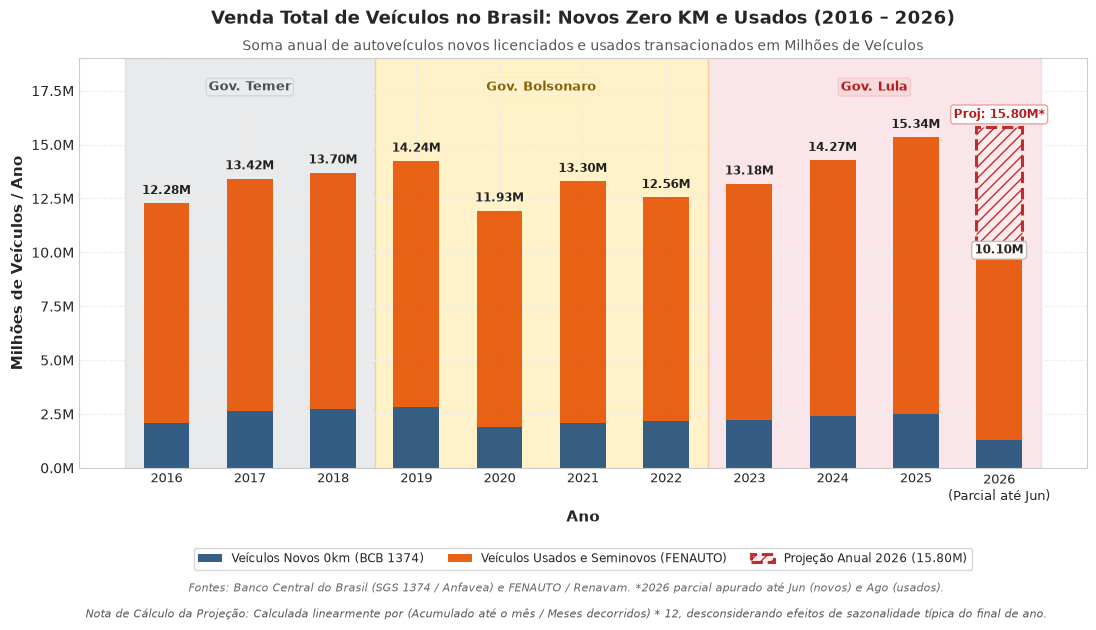

In [4]:
fig, ax = plt.subplots(figsize=(13, 6.5))

y_novos = df_painel['carros_novos_milhoes']
y_usados = df_painel['carros_usados_milhoes']
y_total = y_novos + y_usados

# Projeção de 2026: Novos (2.23M) + Usados (13.20M) = 15.43M
proj_novos = proj_veic / 1e6
proj_usados = 13.20
proj_total = proj_novos + proj_usados

real_2026 = y_total.iloc[-1]
diff_proj_2026 = proj_total - real_2026

# Barras empilhadas para os dados realizados
bars_novos = ax.bar(anos, y_novos, width=0.55, label='Veículos Novos 0km (BCB 1374)', color='#1F4E79', alpha=0.9)
bars_usados = ax.bar(anos, y_usados, width=0.55, bottom=y_novos, label='Veículos Usados e Seminovos (FENAUTO)', color='#E65100', alpha=0.9)

# Barra tracejada da projeção de fechamento para 2026
bar_proj = ax.bar(2026, diff_proj_2026, bottom=real_2026, width=0.55,
                  edgecolor='#B71C1C', linestyle='--', linewidth=2.2, color='#FFEBEE', hatch='///', alpha=0.9,
                  label=f'Projeção Anual 2026 ({proj_total:.2f}M)')

aplicar_faixas_governos(ax, ylim=(0, 19.0))
ax.set_title('Venda Total de Veículos no Brasil: Novos Zero KM e Usados (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Soma anual de autoveículos novos licenciados e usados transacionados em Milhões de Veículos', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.06, f'Fontes: Banco Central do Brasil (SGS 1374 / Anfavea) e FENAUTO / Renavam. *2026 parcial apurado até {mes_veic} (novos) e Ago (usados).', 
         ha='center', fontsize=8.2, style='italic', color='#666666')
fig.text(0.5, 0.02, 'Nota de Cálculo da Projeção: Calculada linearmente por (Acumulado até o mês / Meses decorridos) * 12, desconsiderando efeitos de sazonalidade típica do final de ano.', 
         ha='center', fontsize=7.8, style='italic', color='#555555')

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Milhões de Veículos / Ano', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else f"2026\n(Parcial até {mes_veic})" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1fM'))

# Rótulos com o valor total no topo de cada barra
for a, tot in zip(anos, y_total):
    if a != 2026:
        ax.text(a, tot + 0.30, f"{tot:.2f}M", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#212121')
    else:
        # Rótulo do valor realizado em 2026 (mesmo formato dos outros anos, com fundo branco para contraste)
        ax.text(a, tot, f"{tot:.2f}M", ha='center', va='center', fontsize=8.5, fontweight='bold', color='#212121',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#BDBDBD', alpha=0.95))
        # Rótulo no topo da projeção tracejada com fundo branco
        ax.text(a, proj_total + 0.30, f"Proj: {proj_total:.2f}M*", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#B71C1C',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#EF9A9A', alpha=0.95))

# Legenda fora do gráfico (abaixo do eixo X)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=True, fontsize=8.5)
plt.subplots_adjust(top=0.88, bottom=0.25)
plt.show()


## 🚗 Gráfico 1B: Venda Mensal de Veículos Novos Zero KM no Brasil (2016 – 2026)
Evolução mês a mês dos licenciamentos de autoveículos novos pelas concessionárias em **Milhares de Veículos por Mês** (Anfavea / BCB SGS 1374), apresentado exclusivamente em gráfico de barras com rótulos e faixas por governos.


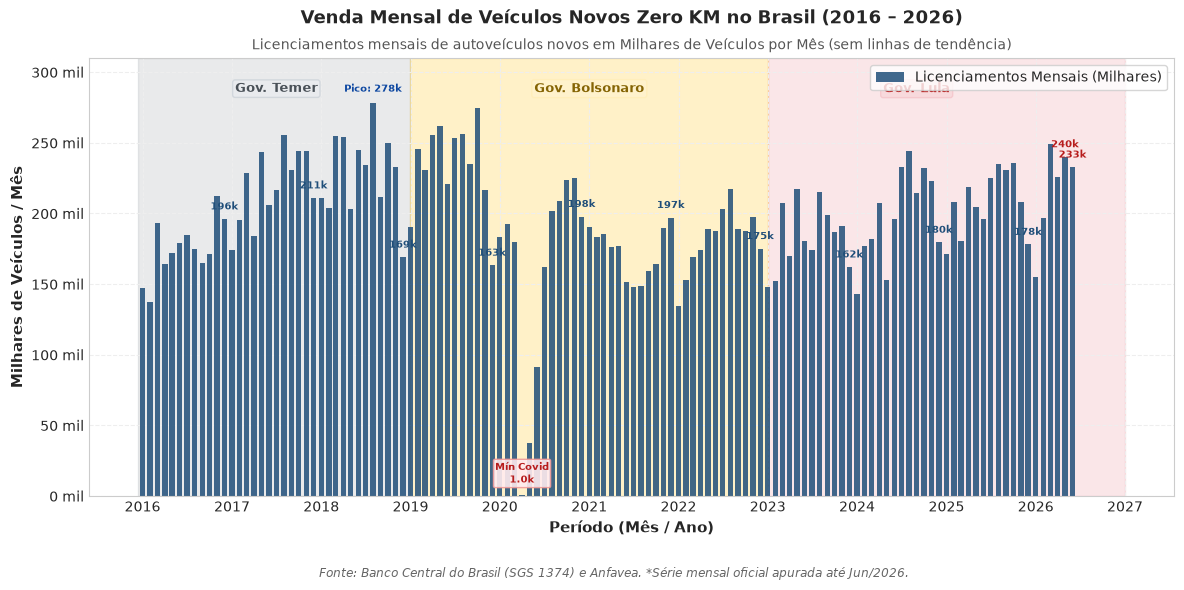

In [5]:
df_veic_m = series_mensais['carros_novos_vendidos'].copy()
df_veic_m['milhares'] = df_veic_m['valor'] / 1000.0

fig, ax = plt.subplots(figsize=(14, 6))

# Apenas gráfico de barras
bars = ax.bar(df_veic_m['data'], df_veic_m['milhares'], width=22, color='#1F4E79', alpha=0.85, label='Licenciamentos Mensais (Milhares)')

aplicar_faixas_governos_datas(ax, ylim=(0, 310))

ax.set_title('Venda Mensal de Veículos Novos Zero KM no Brasil (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Licenciamentos mensais de autoveículos novos em Milhares de Veículos por Mês (sem linhas de tendência)', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.015, f'Fonte: Banco Central do Brasil (SGS 1374) e Anfavea. *Série mensal oficial apurada até {mes_veic}/2026.', 
         ha='center', fontsize=8.5, style='italic', color='#666666')

ax.set_xlabel('Período (Mês / Ano)', fontsize=11, fontweight='bold')
ax.set_ylabel('Milhares de Veículos / Mês', fontsize=11, fontweight='bold')
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f mil'))

# Formatação temporal do eixo X
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[7]))

# Rótulos nas barras com destaque para fechamentos de ano, extremos e 2026
for idx, row in df_veic_m.iterrows():
    d = row['data']
    v = row['milhares']
    is_dez = (d.month == 12)
    is_covid_min = (d.year == 2020 and d.month == 4)
    is_recent = (d.year == 2026 and d.month >= 5)
    is_max = (v == df_veic_m['milhares'].max())
    
    if is_covid_min:
        ax.text(d, v + 6, f"Mín Covid\n{v:.1f}k", ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#B71C1C',
                bbox=dict(boxstyle='round,pad=0.15', facecolor='#FFEBEE', edgecolor='#EF9A9A', alpha=0.9))
    elif is_max:
        ax.text(d, v + 6, f"Pico: {v:.0f}k", ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#0D47A1')
    elif is_dez:
        ax.text(d, v + 5, f"{v:.0f}k", ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#1F4E79')
    elif is_recent:
        ax.text(d, v + 5, f"{v:.0f}k", ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#B71C1C')

ax.legend(loc='upper right', frameon=True)
plt.subplots_adjust(top=0.88, bottom=0.15)
plt.show()


## 🏠 Gráfico 2: Quantidade de Imóveis Financiados pelo SBPE (2016 – 2026)
Total oficial de unidades habitacionais adquiridas através de novos financiamentos imobiliários com recursos do SBPE a pessoas físicas em **Milhares de Imóveis** (100% via API do Banco Central SGS 20703).
A barra do ano 2026 exibe o acumulado realizado até o momento e o **bloco tracejado superior** indica a **projeção anual de fechamento**.


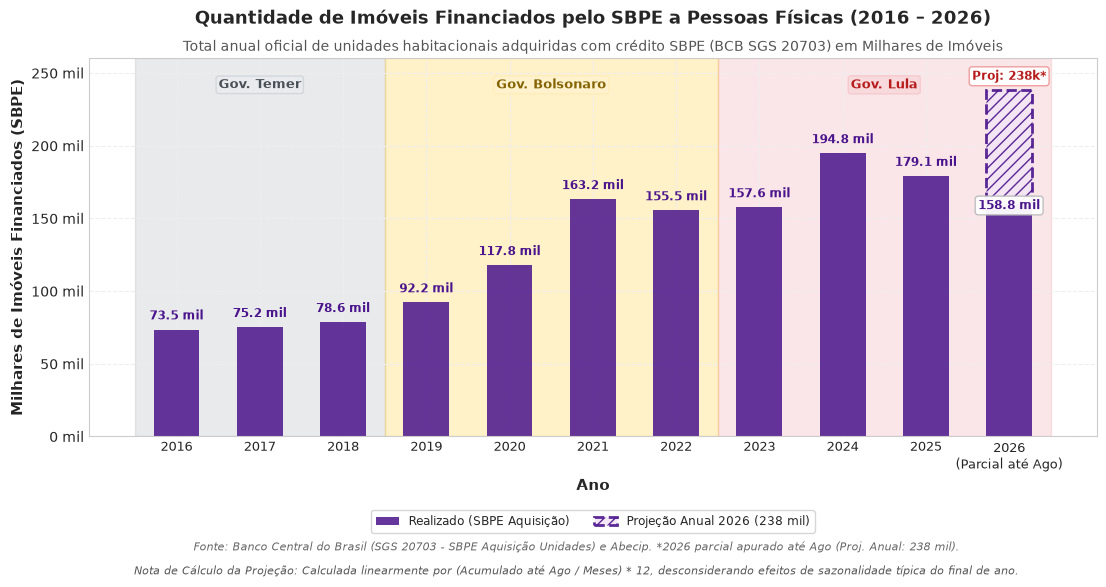

In [6]:
fig, ax = plt.subplots(figsize=(13, 6))

qtd_imob = df_painel['imoveis_unidades_sbpe_milhares']
proj_qtd_imob = (proj_imob_u / 1000.0)
real_2026_imob = qtd_imob.iloc[-1]
diff_proj_imob = proj_qtd_imob - real_2026_imob

# Barras realizadas
bars = ax.bar(anos, qtd_imob, width=0.55, color='#4A148C', alpha=0.85, label='Realizado (SBPE Aquisição)')

# Barra tracejada da projeção 2026
ax.bar(2026, diff_proj_imob, bottom=real_2026_imob, width=0.55,
       edgecolor='#4A148C', linestyle='--', linewidth=2.0, color='#F3E5F5', hatch='///', alpha=0.9,
       label=f'Projeção Anual 2026 ({proj_qtd_imob:.0f} mil)')

aplicar_faixas_governos(ax, ylim=(0, 260))
ax.set_title('Quantidade de Imóveis Financiados pelo SBPE a Pessoas Físicas (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Total anual oficial de unidades habitacionais adquiridas com crédito SBPE (BCB SGS 20703) em Milhares de Imóveis', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.06, f'Fonte: Banco Central do Brasil (SGS 20703 - SBPE Aquisição Unidades) e Abecip. *2026 parcial apurado até {mes_imob_u} (Proj. Anual: {proj_qtd_imob:.0f} mil).', 
         ha='center', fontsize=8.2, style='italic', color='#666666')
fig.text(0.5, 0.02, f'Nota de Cálculo da Projeção: Calculada linearmente por (Acumulado até {mes_imob_u} / Meses) * 12, desconsiderando efeitos de sazonalidade típica do final de ano.', 
         ha='center', fontsize=7.8, style='italic', color='#555555')

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Milhares de Imóveis Financiados (SBPE)', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else f"2026\n(Parcial até {mes_imob_u})" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f mil'))

for a, v in zip(anos, qtd_imob):
    if a != 2026:
        ax.text(a, v + 5, f"{v:.1f} mil", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#4A148C')
    else:
        # Rótulo do realizado em 2026 (mesmo formato dos outros anos, com fundo branco para contraste)
        ax.text(a, v, f"{v:.1f} mil", ha='center', va='center', fontsize=8.5, fontweight='bold', color='#4A148C',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#BDBDBD', alpha=0.95))
        # Rótulo no topo da projeção tracejada com fundo branco
        ax.text(a, proj_qtd_imob + 5, f"Proj: {proj_qtd_imob:.0f}k*", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#B71C1C',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#EF9A9A', alpha=0.95))

# Legenda fora do gráfico (abaixo do eixo X)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=True, fontsize=8.5)
plt.subplots_adjust(top=0.88, bottom=0.25)
plt.show()


## 🛍️ Gráfico 3: Faturamento Nominal do Comércio Varejista Ampliado (2016 – 2026)
Receita bruta operacional de vendas do varejo ampliado nacional em **R$ Trilhões**.
A barra de 2026 inclui o acumulado apurado e a **extensão tracejada** representando a **projeção anual de fechamento**.


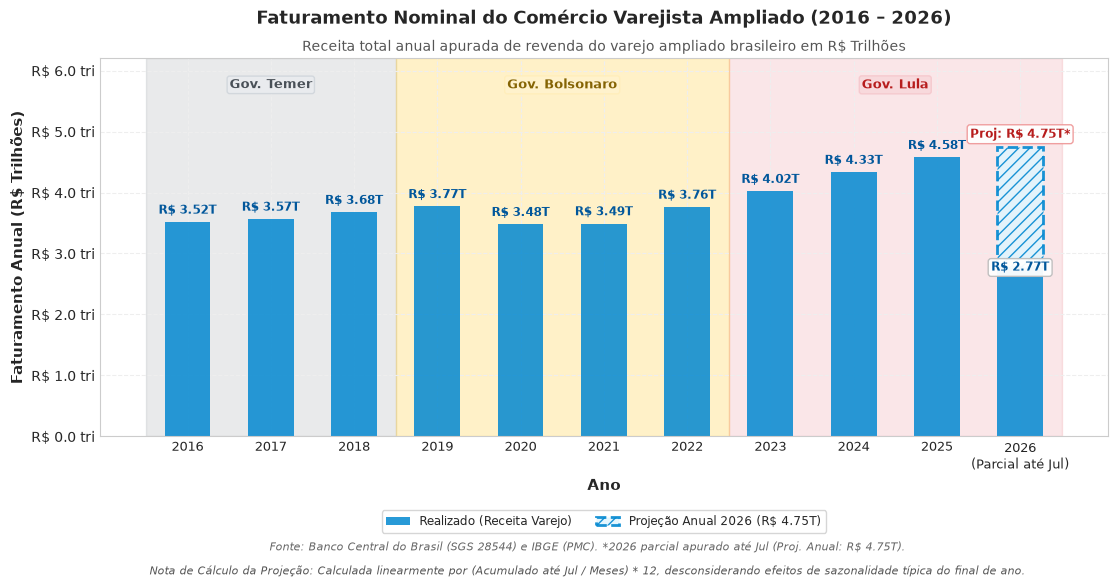

In [7]:
fig, ax = plt.subplots(figsize=(13, 6))

fat_tri = df_painel['comercio_faturamento_rs_tri']
proj_fat = proj_com / 1e6
real_fat_2026 = fat_tri.iloc[-1]
diff_proj_com = proj_fat - real_fat_2026

bars = ax.bar(anos, fat_tri, width=0.55, color='#0288D1', alpha=0.85, label='Realizado (Receita Varejo)')

# Barra tracejada da projeção
ax.bar(2026, diff_proj_com, bottom=real_fat_2026, width=0.55,
       edgecolor='#0288D1', linestyle='--', linewidth=2.0, color='#E1F5FE', hatch='///', alpha=0.9,
       label=f'Projeção Anual 2026 (R$ {proj_fat:.2f}T)')

aplicar_faixas_governos(ax, ylim=(0, 6.2))
ax.set_title('Faturamento Nominal do Comércio Varejista Ampliado (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Receita total anual apurada de revenda do varejo ampliado brasileiro em R$ Trilhões', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.06, f'Fonte: Banco Central do Brasil (SGS 28544) e IBGE (PMC). *2026 parcial apurado até {mes_com} (Proj. Anual: R$ {proj_fat:.2f}T).', 
         ha='center', fontsize=8.2, style='italic', color='#666666')
fig.text(0.5, 0.02, f'Nota de Cálculo da Projeção: Calculada linearmente por (Acumulado até {mes_com} / Meses) * 12, desconsiderando efeitos de sazonalidade típica do final de ano.', 
         ha='center', fontsize=7.8, style='italic', color='#555555')

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Faturamento Anual (R$ Trilhões)', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else f"2026\n(Parcial até {mes_com})" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('R$ %.1f tri'))

for a, v in zip(anos, fat_tri):
    if a != 2026:
        ax.text(a, v + 0.09, f"R$ {v:.2f}T", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#01579B')
    else:
        # Rótulo do realizado em 2026 (mesmo formato dos outros anos, com fundo branco para contraste)
        ax.text(a, v, f"R$ {v:.2f}T", ha='center', va='center', fontsize=8.5, fontweight='bold', color='#01579B',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#BDBDBD', alpha=0.95))
        # Rótulo no topo da projeção tracejada com fundo branco
        ax.text(a, proj_fat + 0.10, f"Proj: R$ {proj_fat:.2f}T*", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#B71C1C',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#EF9A9A', alpha=0.95))

# Legenda fora do gráfico (abaixo do eixo X)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=True, fontsize=8.5)
plt.subplots_adjust(top=0.88, bottom=0.25)
plt.show()


## ✈️ Gráfico 4: Gastos de Brasileiros em Viagens ao Exterior (2016 – 2026)
Despesas internacionais com viagens de turismo e negócios no exterior em **US$ Bilhões**.
A barra de 2026 exibe o gasto apurado e o **bloco tracejado** indicando a **projeção anual**.


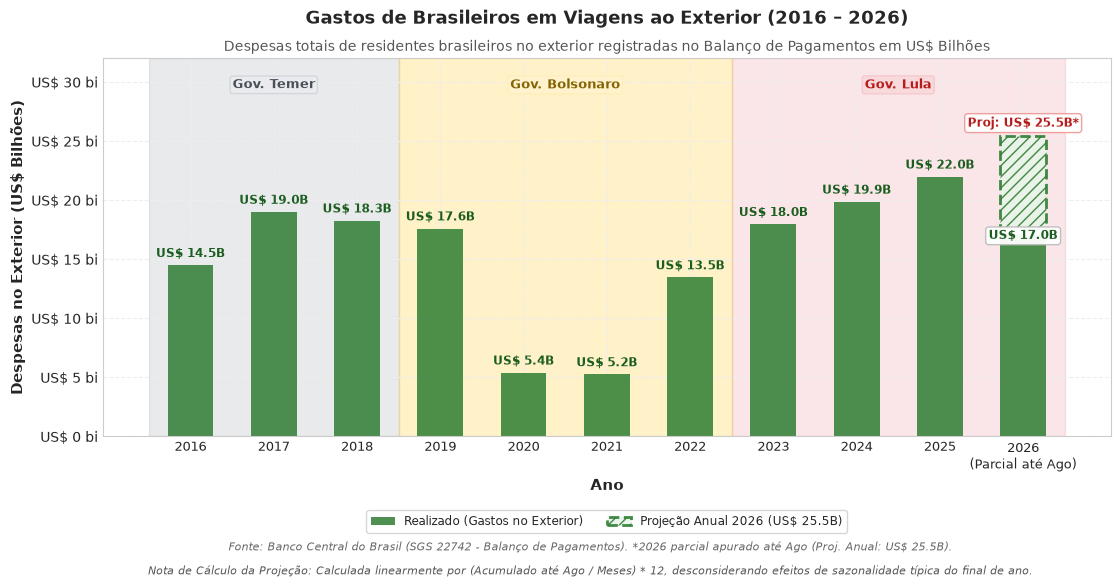

In [8]:
fig, ax = plt.subplots(figsize=(13, 6))

gastos_bi = df_painel['gastos_exterior_usd_bi']
proj_gastos = proj_viag / 1000.0
real_gastos_2026 = gastos_bi.iloc[-1]
diff_proj_viag = proj_gastos - real_gastos_2026

bars = ax.bar(anos, gastos_bi, width=0.55, color='#2E7D32', alpha=0.85, label='Realizado (Gastos no Exterior)')

# Barra tracejada da projeção
ax.bar(2026, diff_proj_viag, bottom=real_gastos_2026, width=0.55,
       edgecolor='#2E7D32', linestyle='--', linewidth=2.0, color='#E8F5E9', hatch='///', alpha=0.9,
       label=f'Projeção Anual 2026 (US$ {proj_gastos:.1f}B)')

aplicar_faixas_governos(ax, ylim=(0, 32))
ax.set_title('Gastos de Brasileiros em Viagens ao Exterior (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Despesas totais de residentes brasileiros no exterior registradas no Balanço de Pagamentos em US$ Bilhões', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.06, f'Fonte: Banco Central do Brasil (SGS 22742 - Balanço de Pagamentos). *2026 parcial apurado até {mes_viag} (Proj. Anual: US$ {proj_gastos:.1f}B).', 
         ha='center', fontsize=8.2, style='italic', color='#666666')
fig.text(0.5, 0.02, f'Nota de Cálculo da Projeção: Calculada linearmente por (Acumulado até {mes_viag} / Meses) * 12, desconsiderando efeitos de sazonalidade típica do final de ano.', 
         ha='center', fontsize=7.8, style='italic', color='#555555')

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Despesas no Exterior (US$ Bilhões)', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else f"2026\n(Parcial até {mes_viag})" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('US$ %.0f bi'))

for a, v in zip(anos, gastos_bi):
    if a != 2026:
        ax.text(a, v + 0.45, f"US$ {v:.1f}B", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1B5E20')
    else:
        # Rótulo do realizado em 2026 (mesmo formato dos outros anos, com fundo branco para contraste)
        ax.text(a, v, f"US$ {v:.1f}B", ha='center', va='center', fontsize=8.5, fontweight='bold', color='#1B5E20',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#BDBDBD', alpha=0.95))
        # Rótulo no topo da projeção tracejada com fundo branco
        ax.text(a, proj_gastos + 0.50, f"Proj: US$ {proj_gastos:.1f}B*", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#B71C1C',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#EF9A9A', alpha=0.95))

# Legenda fora do gráfico (abaixo do eixo X)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=True, fontsize=8.5)
plt.subplots_adjust(top=0.88, bottom=0.25)
plt.show()


## 🌾 Gráfico 5: Agronegócio — Lucro e Saldo Comercial Líquido das Exportações (2016 – 2026)
Saldo comercial líquido de divisas (Exportações do Agro menos Importações do Agro) em **US$ Bilhões**.
A barra de 2026 inclui o superávit apurado até agosto e o **bloco tracejado superior** com a **projeção de fechamento**.


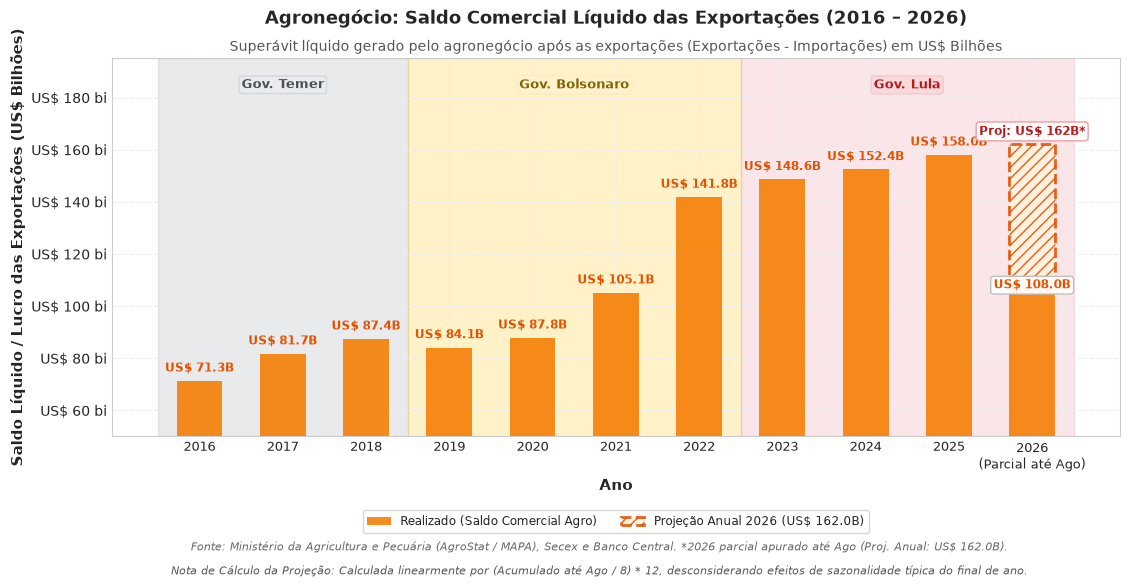

In [9]:
fig, ax = plt.subplots(figsize=(13, 6))

saldo_agro = df_painel['agro_saldo_export_usd_bi']
proj_agro = 162.0
real_agro_2026 = saldo_agro.iloc[-1]
diff_proj_agro = proj_agro - real_agro_2026

bars = ax.bar(anos, saldo_agro, width=0.55, color='#F57C00', alpha=0.88, label='Realizado (Saldo Comercial Agro)')

# Barra tracejada da projeção
ax.bar(2026, diff_proj_agro, bottom=real_agro_2026, width=0.55,
       edgecolor='#E65100', linestyle='--', linewidth=2.0, color='#FFF3E0', hatch='///', alpha=0.9,
       label=f'Projeção Anual 2026 (US$ {proj_agro:.1f}B)')

# Zoom no eixo Y (de 50 a 195)
aplicar_faixas_governos(ax, ylim=(50, 195))
ax.set_title('Agronegócio: Saldo Comercial Líquido das Exportações (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Superávit líquido gerado pelo agronegócio após as exportações (Exportações - Importações) em US$ Bilhões', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.06, 'Fonte: Ministério da Agricultura e Pecuária (AgroStat / MAPA), Secex e Banco Central. *2026 parcial apurado até Ago (Proj. Anual: US$ 162.0B).', 
         ha='center', fontsize=8.2, style='italic', color='#666666')
fig.text(0.5, 0.02, 'Nota de Cálculo da Projeção: Calculada linearmente por (Acumulado até Ago / 8) * 12, desconsiderando efeitos de sazonalidade típica do final de ano.', 
         ha='center', fontsize=7.8, style='italic', color='#555555')

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Saldo Líquido / Lucro das Exportações (US$ Bilhões)', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else "2026\n(Parcial até Ago)" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('US$ %.0f bi'))

for a, v in zip(anos, saldo_agro):
    if a != 2026:
        ax.text(a, v + 2.5, f"US$ {v:.1f}B", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#E65100')
    else:
        # Rótulo do realizado em 2026 (mesmo formato dos outros anos, com fundo branco para contraste)
        ax.text(a, v, f"US$ {v:.1f}B", ha='center', va='center', fontsize=8.5, fontweight='bold', color='#E65100',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#BDBDBD', alpha=0.95))
        # Rótulo no topo da projeção tracejada com fundo branco
        ax.text(a, proj_agro + 2.5, f"Proj: US$ {proj_agro:.0f}B*", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#B71C1C',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#EF9A9A', alpha=0.95))

# Legenda fora do gráfico (abaixo do eixo X)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=True, fontsize=8.5)
plt.subplots_adjust(top=0.88, bottom=0.25)
plt.show()


## 💼 Gráfico 6: Pessoas com Carteira de Trabalho Assinada / CLT (2016 – 2026)
Estoque médio de trabalhadores formais ocupados no setor privado brasileiro em **Milhões de Pessoas**.


## 💼 Gráfico 6: Pessoas com Carteira de Trabalho Assinada / CLT (2016 – 2026)
Estoque médio de trabalhadores formais ocupados no setor privado brasileiro em **Milhões de Pessoas**.


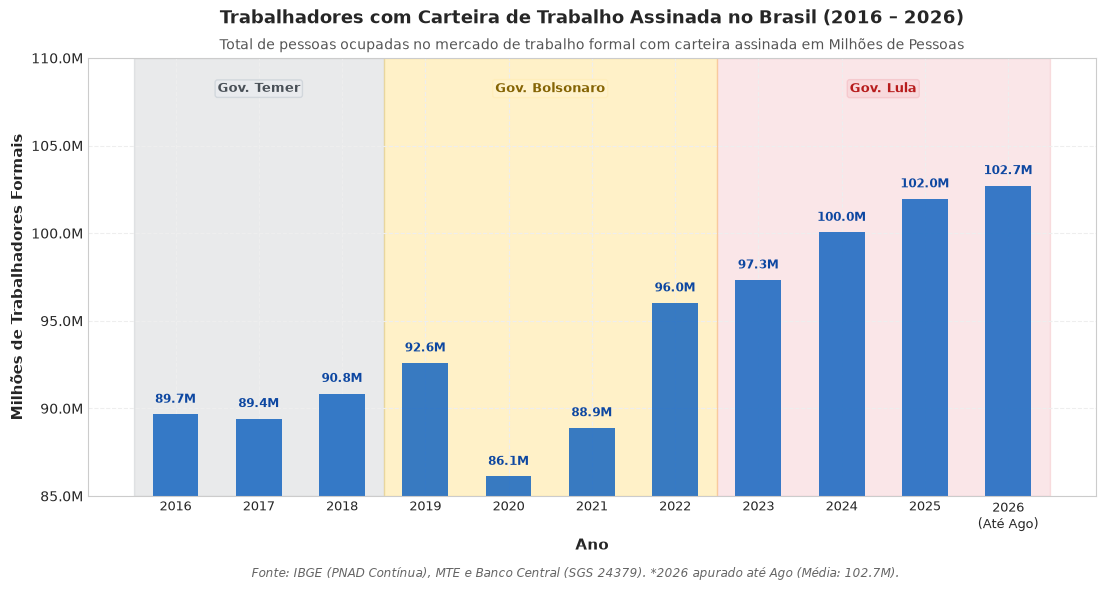

In [10]:
fig, ax = plt.subplots(figsize=(13, 6))

clt = df_painel['clt_carteira_milhoes']
bars = ax.bar(anos, clt, width=0.55, color='#1565C0', alpha=0.85, label='Trabalhadores Formais CLT')

# Ajuste do eixo Y solicitado: de 85 a 110 Milhões
aplicar_faixas_governos(ax, ylim=(85, 110))
ax.set_ylim(85, 110)
ax.set_title('Trabalhadores com Carteira de Trabalho Assinada no Brasil (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Total de pessoas ocupadas no mercado de trabalho formal com carteira assinada em Milhões de Pessoas', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.015, f'Fonte: IBGE (PNAD Contínua), MTE e Banco Central (SGS 24379). *2026 apurado até {mes_clt} (Média: {proj_clt/1000:.1f}M).', 
         ha='center', fontsize=8.5, style='italic', color='#666666')

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Milhões de Trabalhadores Formais', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else f"2026\n(Até {mes_clt})" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1fM'))

for a, v in zip(anos, clt):
    ax.text(a, v + 0.5, f"{v:.1f}M", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#0D47A1')

plt.subplots_adjust(top=0.88, bottom=0.15)
plt.show()


## 🧑‍💼 Gráfico 7: Expansão dos Microempreendedores Individuais — MEIs Ativos (2016 – 2026)
Estoque total de MEIs registrados e ativos no Brasil em **Milhões de MEIs**.


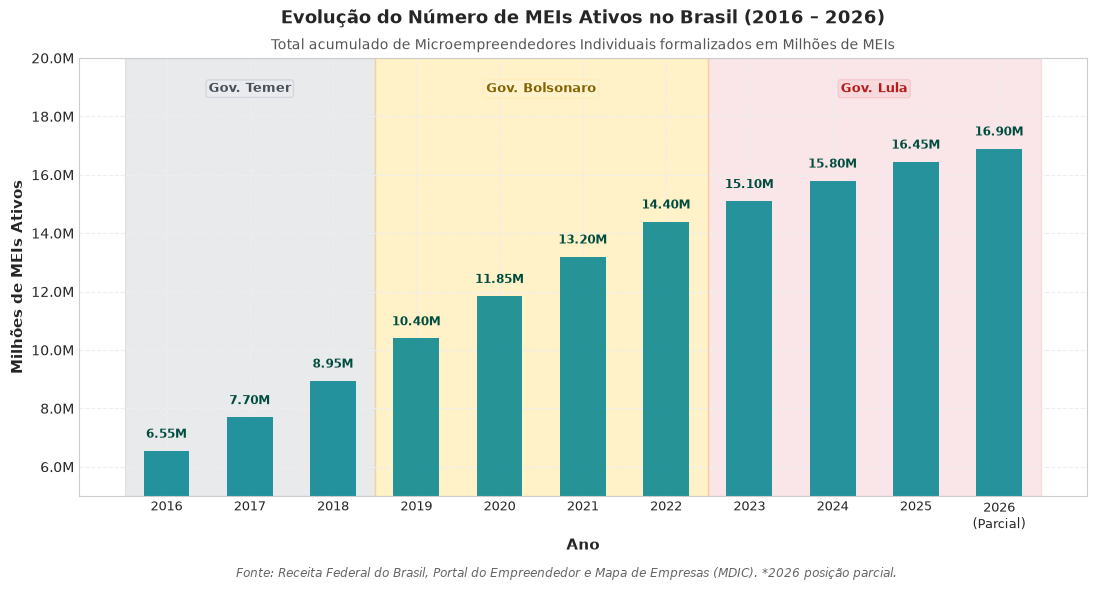

In [11]:
fig, ax = plt.subplots(figsize=(13, 6))

meis = df_painel['meis_ativos_milhoes']
bars = ax.bar(anos, meis, width=0.55, color='#00838F', alpha=0.85, label='MEIs Ativos')

# Ajuste do eixo Y solicitado: de 5 a 20 Milhões
aplicar_faixas_governos(ax, ylim=(5, 20))
ax.set_ylim(5, 20)
ax.set_title('Evolução do Número de MEIs Ativos no Brasil (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Total acumulado de Microempreendedores Individuais formalizados em Milhões de MEIs', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')
fig.text(0.5, 0.015, 'Fonte: Receita Federal do Brasil, Portal do Empreendedor e Mapa de Empresas (MDIC). *2026 posição parcial.', 
         ha='center', fontsize=8.5, style='italic', color='#666666')

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Milhões de MEIs Ativos', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else "2026\n(Parcial)" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1fM'))

for a, v in zip(anos, meis):
    ax.text(a, v + 0.35, f"{v:.2f}M", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#004D40')

plt.subplots_adjust(top=0.88, bottom=0.15)
plt.show()


## 🍞 Gráfico 8: Poder de Compra — Custo de 1 Cesta Básica (% do Salário Mínimo)
Parcela da remuneração mínima necessária para adquirir 1 Cesta Básica oficial em **% do Salário Mínimo** (100% oficial via API DIEESE / Banco Central SGS 7493).
Inclui os marcos dos **impactos políticos e choques de preços no final de 2020**, a **retomada dos estoques estratégicos da Conab em 2023** e a **vigência da Reforma Tributária com Alíquota Zero na Cesta Básica a partir de 2026**.


/home/hianara/Voluntariado/venv_pmi/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128204 (\N{PUSHPIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


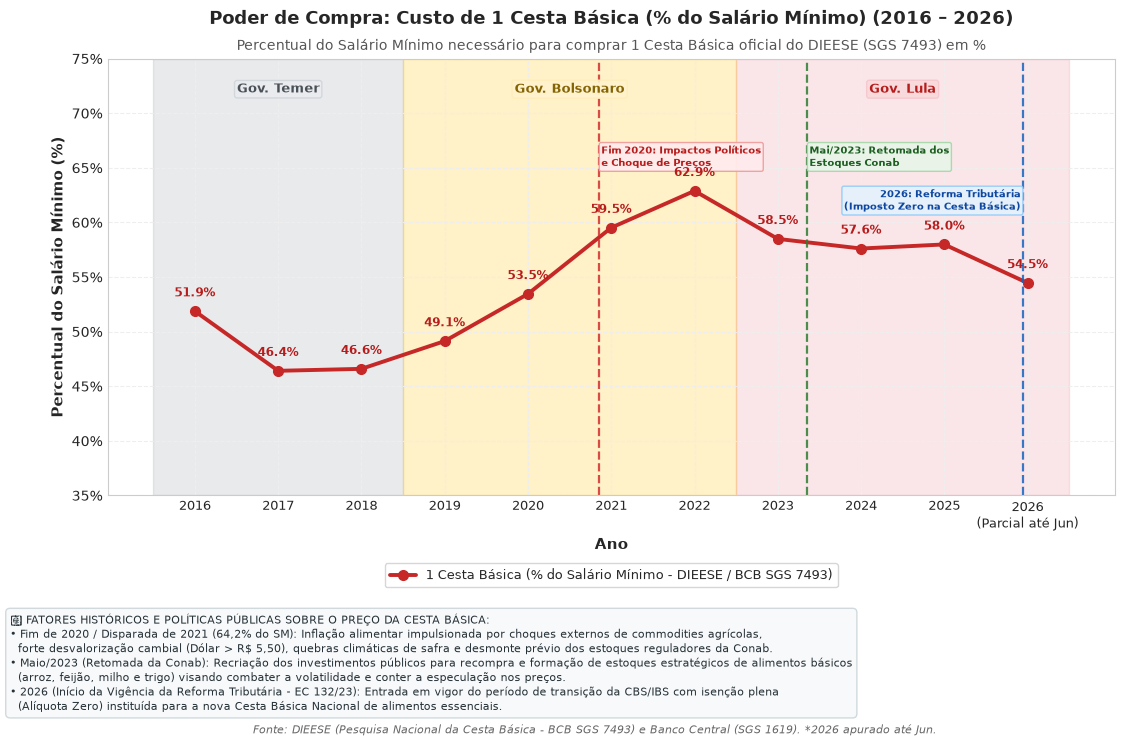

In [12]:
fig, ax = plt.subplots(figsize=(13, 7.8))

pct_sm = df_painel['cesta_pct_sm']

ax.plot(anos, pct_sm, color='#C62828', marker='o', linewidth=2.8, markersize=7, label='1 Cesta Básica (% do Salário Mínimo - DIEESE / BCB SGS 7493)')

aplicar_faixas_governos(ax, ylim=(35, 75))
ax.set_title('Poder de Compra: Custo de 1 Cesta Básica (% do Salário Mínimo) (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Percentual do Salário Mínimo necessário para comprar 1 Cesta Básica oficial do DIEESE (SGS 7493) em %', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')

# 1. Linha pouco antes de 2021: Fim de 2020 (Impactos Políticos e Choques)
ax.axvline(x=2020.85, color='#D32F2F', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2020.88, 66.0, 'Fim 2020: Impactos Políticos\ne Choque de Preços', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#B71C1C',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFEBEE', edgecolor='#EF9A9A', alpha=0.9))

# 2. Linha em 2023: Retomada dos Estoques Estratégicos da Conab
ax.axvline(x=2023.35, color='#2E7D32', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2023.38, 66.0, 'Mai/2023: Retomada dos\nEstoques Conab', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#1B5E20',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#E8F5E9', edgecolor='#A5D6A7', alpha=0.9))

# 3. Linha em 2026: Vigência da Reforma Tributária (Alíquota Zero na Cesta Básica)
ax.axvline(x=2025.95, color='#1565C0', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2025.92, 62.0, '2026: Reforma Tributária\n(Imposto Zero na Cesta Básica)', 
        ha='right', va='center', fontsize=7.2, fontweight='bold', color='#0D47A1',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#E3F2FD', edgecolor='#90CAF9', alpha=0.9))

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Percentual do Salário Mínimo (%)', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else f"2026\n(Parcial até {mes_cesta_bcb})" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f%%'))

# Legenda abaixo do eixo X
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=True, fontsize=9.2)

for a, sm in zip(anos, pct_sm):
    ax.text(a, sm + 1.1, f"{sm:.1f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#B71C1C')

# Comentários explicativos posicionados abaixo do gráfico
comentarios_cesta = (
    "📌 FATORES HISTÓRICOS E POLÍTICAS PÚBLICAS SOBRE O PREÇO DA CESTA BÁSICA:\n"
    "• Fim de 2020 / Disparada de 2021 (64,2% do SM): Inflação alimentar impulsionada por choques externos de commodities agrícolas,\n"
    "  forte desvalorização cambial (Dólar > R$ 5,50), quebras climáticas de safra e desmonte prévio dos estoques reguladores da Conab.\n"
    "• Maio/2023 (Retomada da Conab): Recriação dos investimentos públicos para recompra e formação de estoques estratégicos de alimentos básicos\n"
    "  (arroz, feijão, milho e trigo) visando combater a volatilidade e conter a especulação nos preços.\n"
    "• 2026 (Início da Vigência da Reforma Tributária - EC 132/23): Entrada em vigor do período de transição da CBS/IBS com isenção plena\n"
    "  (Alíquota Zero) instituída para a nova Cesta Básica Nacional de alimentos essenciais."
)
fig.text(0.05, 0.045, comentarios_cesta, fontsize=7.7, color='#263238', linespacing=1.35,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F8F9FA', edgecolor='#CFD8DC', alpha=0.95))

fig.text(0.5, 0.015, f'Fonte: DIEESE (Pesquisa Nacional da Cesta Básica - BCB SGS 7493) e Banco Central (SGS 1619). *2026 apurado até {mes_cesta_bcb}.', 
         ha='center', fontsize=8.0, style='italic', color='#666666')

plt.subplots_adjust(top=0.88, bottom=0.32)
plt.show()


## 🔥 Gráfico 9: Poder de Compra — 1 Botijão de Gás GLP 13kg (% do Salário Mínimo)
Peso do custo de 1 botijão de gás doméstico no orçamento em **% do Salário Mínimo**.
Inclui os marcos da **adoção do PPI (2016)**, da **revogação do PPI e adoção do refino nacional (2023)** e da **retenção de lucros da Petrobras para amortecimento contra conflitos geopolíticos internacionais (2024)**.


/home/hianara/Voluntariado/venv_pmi/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


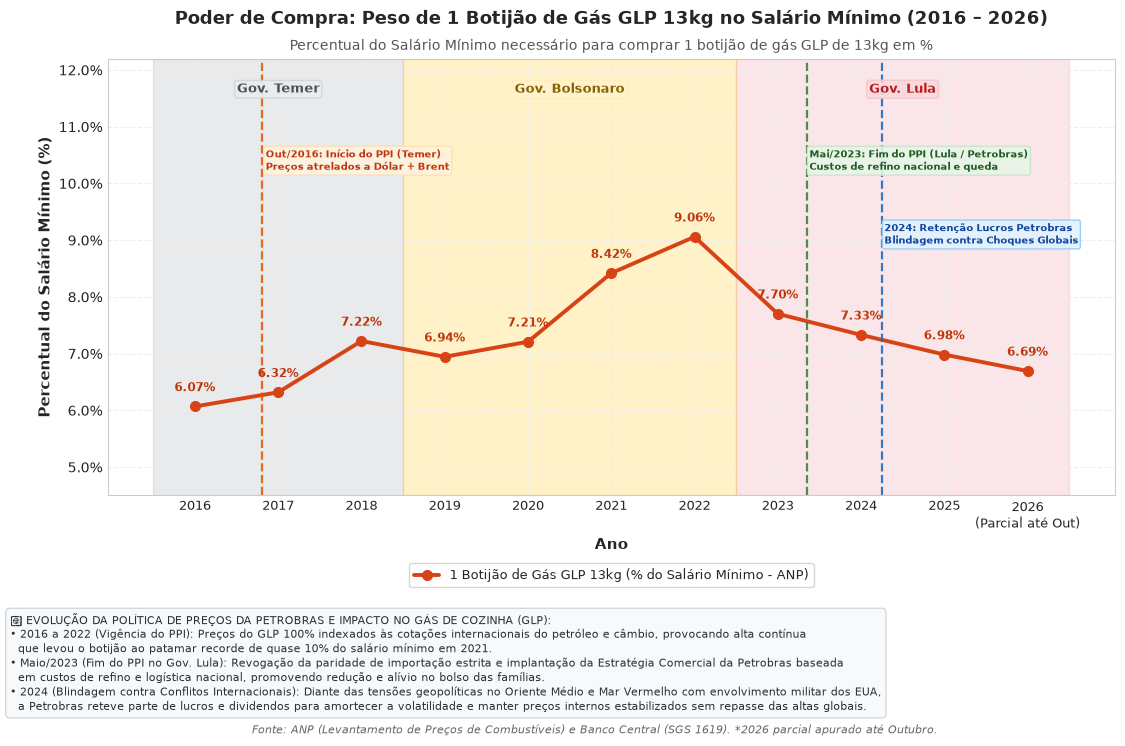

In [13]:
fig, ax = plt.subplots(figsize=(13, 7.8))

gas_sm = df_painel['gas_pct_sm']

ax.plot(anos, gas_sm, color='#D84315', marker='o', linewidth=2.8, markersize=7, label='1 Botijão de Gás GLP 13kg (% do Salário Mínimo - ANP)')

aplicar_faixas_governos(ax, ylim=(4.5, 12.2))
ax.set_title('Poder de Compra: Peso de 1 Botijão de Gás GLP 13kg no Salário Mínimo (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Percentual do Salário Mínimo necessário para comprar 1 botijão de gás GLP de 13kg em %', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')

# Linhas tracejadas de marcos do PPI e Petrobras
ax.axvline(x=2016.8, color='#E65100', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2016.85, 10.4, 'Out/2016: Início do PPI (Temer)\nPreços atrelados a Dólar + Brent', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#BF360C',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3E0', edgecolor='#FFE0B2', alpha=0.9))

ax.axvline(x=2023.35, color='#2E7D32', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2023.38, 10.4, 'Mai/2023: Fim do PPI (Lula / Petrobras)\nCustos de refino nacional e queda', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#1B5E20',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#E8F5E9', edgecolor='#C8E6C9', alpha=0.9))

ax.axvline(x=2024.25, color='#1565C0', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2024.28, 9.1, '2024: Retenção Lucros Petrobras\nBlindagem contra Choques Globais', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#0D47A1',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#E3F2FD', edgecolor='#90CAF9', alpha=0.9))

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Percentual do Salário Mínimo (%)', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else "2026\n(Parcial até Out)" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f%%'))

# Legenda abaixo do eixo X
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=True, fontsize=9.2)

for a, sm in zip(anos, gas_sm):
    ax.text(a, sm + 0.22, f"{sm:.2f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#BF360C')

# Comentários explicativos posicionados abaixo do gráfico
comentarios_gas = (
    "💡 EVOLUÇÃO DA POLÍTICA DE PREÇOS DA PETROBRAS E IMPACTO NO GÁS DE COZINHA (GLP):\n"
    "• 2016 a 2022 (Vigência do PPI): Preços do GLP 100% indexados às cotações internacionais do petróleo e câmbio, provocando alta contínua\n"
    "  que levou o botijão ao patamar recorde de quase 10% do salário mínimo em 2021.\n"
    "• Maio/2023 (Fim do PPI no Gov. Lula): Revogação da paridade de importação estrita e implantação da Estratégia Comercial da Petrobras baseada\n"
    "  em custos de refino e logística nacional, promovendo redução e alívio no bolso das famílias.\n"
    "• 2024 (Blindagem contra Conflitos Internacionais): Diante das tensões geopolíticas no Oriente Médio e Mar Vermelho com envolvimento militar dos EUA,\n"
    "  a Petrobras reteve parte de lucros e dividendos para amortecer a volatilidade e manter preços internos estabilizados sem repasse das altas globais."
)
fig.text(0.05, 0.045, comentarios_gas, fontsize=7.7, color='#263238', linespacing=1.35,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F8F9FA', edgecolor='#CFD8DC', alpha=0.95))

fig.text(0.5, 0.015, 'Fonte: ANP (Levantamento de Preços de Combustíveis) e Banco Central (SGS 1619). *2026 parcial apurado até Outubro.', 
         ha='center', fontsize=8.0, style='italic', color='#666666')

plt.subplots_adjust(top=0.88, bottom=0.32)
plt.show()


## ⛽ Gráfico 10: Poder de Compra — 1 Litro de Gasolina Comum (% do Salário Mínimo)
Custo de 1 litro de combustível em relação ao Salário Mínimo em **% do Salário Mínimo**.
Inclui os marcos históricos do início do **PPI (2016)**, do **fim do PPI (2023)** e da **blindagem de preços contra choques geopolíticos internacionais da Petrobras (2024)**.


/home/hianara/Voluntariado/venv_pmi/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


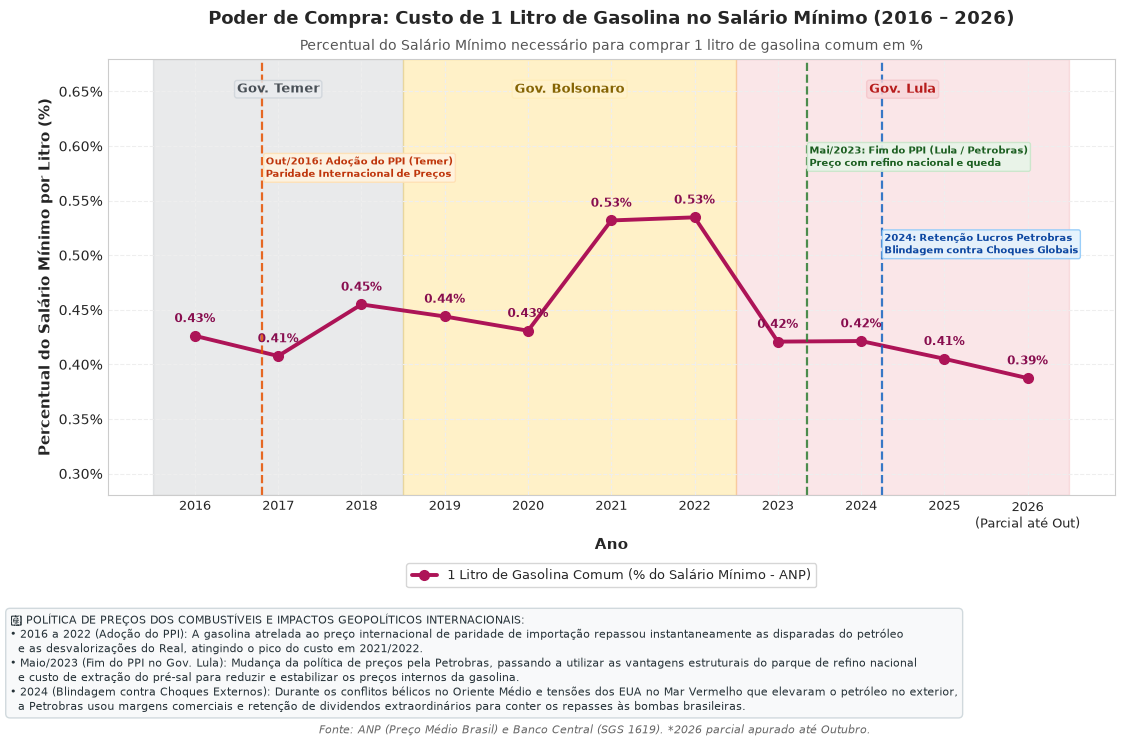

In [14]:
fig, ax = plt.subplots(figsize=(13, 7.8))

gasol_sm = df_painel['gasolina_pct_sm']

ax.plot(anos, gasol_sm, color='#AD1457', marker='o', linewidth=2.8, markersize=7, label='1 Litro de Gasolina Comum (% do Salário Mínimo - ANP)')

aplicar_faixas_governos(ax, ylim=(0.28, 0.68))
ax.set_title('Poder de Compra: Custo de 1 Litro de Gasolina no Salário Mínimo (2016 – 2026)', fontsize=13, fontweight='bold', pad=25)
ax.text(0.5, 1.02, 'Percentual do Salário Mínimo necessário para comprar 1 litro de gasolina comum em %', 
        transform=ax.transAxes, ha='center', fontsize=10, color='#555555')

# Linhas tracejadas de marcos do PPI e Petrobras
ax.axvline(x=2016.8, color='#E65100', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2016.85, 0.58, 'Out/2016: Adoção do PPI (Temer)\nParidade Internacional de Preços', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#BF360C',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#FFF3E0', edgecolor='#FFE0B2', alpha=0.9))

ax.axvline(x=2023.35, color='#2E7D32', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2023.38, 0.59, 'Mai/2023: Fim do PPI (Lula / Petrobras)\nPreço com refino nacional e queda', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#1B5E20',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#E8F5E9', edgecolor='#C8E6C9', alpha=0.9))

ax.axvline(x=2024.25, color='#1565C0', linestyle='--', linewidth=1.6, alpha=0.85)
ax.text(2024.28, 0.51, '2024: Retenção Lucros Petrobras\nBlindagem contra Choques Globais', 
        ha='left', va='center', fontsize=7.2, fontweight='bold', color='#0D47A1',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='#E3F2FD', edgecolor='#90CAF9', alpha=0.9))

ax.set_xlabel('Ano', fontsize=11, fontweight='bold')
ax.set_ylabel('Percentual do Salário Mínimo por Litro (%)', fontsize=11, fontweight='bold')
ax.set_xticks(anos)
ax.set_xticklabels([f"{int(a)}" if a != 2026 else "2026\n(Parcial até Out)" for a in anos], fontsize=9)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f%%'))

# Legenda abaixo do eixo X
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=True, fontsize=9.2)

for a, sm in zip(anos, gasol_sm):
    ax.text(a, sm + 0.010, f"{sm:.2f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#880E4F')

# Comentários explicativos posicionados abaixo do gráfico
comentarios_gasol = (
    "💡 POLÍTICA DE PREÇOS DOS COMBUSTÍVEIS E IMPACTOS GEOPOLÍTICOS INTERNACIONAIS:\n"
    "• 2016 a 2022 (Adoção do PPI): A gasolina atrelada ao preço internacional de paridade de importação repassou instantaneamente as disparadas do petróleo\n"
    "  e as desvalorizações do Real, atingindo o pico do custo em 2021/2022.\n"
    "• Maio/2023 (Fim do PPI no Gov. Lula): Mudança da política de preços pela Petrobras, passando a utilizar as vantagens estruturais do parque de refino nacional\n"
    "  e custo de extração do pré-sal para reduzir e estabilizar os preços internos da gasolina.\n"
    "• 2024 (Blindagem contra Choques Externos): Durante os conflitos bélicos no Oriente Médio e tensões dos EUA no Mar Vermelho que elevaram o petróleo no exterior,\n"
    "  a Petrobras usou margens comerciais e retenção de dividendos extraordinários para conter os repasses às bombas brasileiras."
)
fig.text(0.05, 0.045, comentarios_gasol, fontsize=7.7, color='#263238', linespacing=1.35,
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#F8F9FA', edgecolor='#CFD8DC', alpha=0.95))

fig.text(0.5, 0.015, 'Fonte: ANP (Preço Médio Brasil) e Banco Central (SGS 1619). *2026 parcial apurado até Outubro.', 
         ha='center', fontsize=8.0, style='italic', color='#666666')

plt.subplots_adjust(top=0.88, bottom=0.32)
plt.show()


## 📑 3. Exportação dos Dados Consolidados para Excel (2016 – 2026)
Gravamos a tabela consolidada no arquivo Excel `series_historicas_brasil_2010_2025.xlsx` contendo três abas organizadas:
1. **`Series_Historicas_2016_2026`**: Dados oficiais anuais, mercado de veículos novos vs. usados e rácios de poder de compra.
2. **`Veiculos_Vendas_Mensais`**: Série histórica mensal de licenciamentos de veículos novos (2016 a 2026).
3. **`Dicionario_e_Fontes`**: Metadados, órgãos responsáveis e fórmulas de cálculo.


In [15]:
OUTPUT_EXCEL_SERIES = 'series_historicas_brasil_2010_2025.xlsx'
df_export = df_painel.rename(columns={
    'ano': 'Ano',
    'carros_novos_vendidos': 'Veículos Novos Vendidos (Unidades - BCB 1374)',
    'carros_novos_milhoes': 'Veículos Novos Vendidos (Milhões Unidades)',
    'carros_usados_milhoes': 'Veículos Usados Vendidos (Milhões Unidades - FENAUTO)',
    'razao_usados_por_novo': 'Razão Veículos Usados por Novo (Proporção)',
    'imoveis_vendas_rs_bi': 'Venda de Imóveis Financiados PF (R$ Bi - BCB 20704)',
    'imoveis_quantidade_milhares': 'Quantidade Imóveis Financiados Vendidos (Milhares Unidades - Estimado)',
    'imoveis_unidades_sbpe_milhares': 'Quantidade Imóveis Financiados SBPE (Milhares Unidades - BCB 20703 Oficial)',
    'comercio_faturamento_rs_tri': 'Faturamento Comércio Varejista Ampliado (R$ Tri - BCB 28544)',
    'gastos_exterior_usd_bi': 'Gastos de Brasileiros no Exterior (US$ Bi - BCB 22742)',
    'agro_saldo_export_usd_bi': 'Agronegócio - Saldo das Exportações / Lucro Líquido (US$ Bi)',
    'empresas_abertas_milhoes': 'Empresas Novas Abertas (Milhões)',
    'recuperacoes_judiciais': 'Empresas em Recuperação Judicial (Casos - BCB 4392)',
    'producao_industrial_pim': 'Produção Física Industrial (Índice 2022=100 - BCB 21859)',
    'clt_carteira_milhoes': 'Trabalhadores com Carteira Assinada / CLT (Milhões - BCB 24379)',
    'meis_ativos_milhoes': 'MEIs Ativos no Brasil (Milhões)',
    'salario_minimo_rs': 'Salário Mínimo Nominal (R$ - BCB 1619)',
    'salario_medio_rs': 'Rendimento Médio Habitual Nominal (R$ - BCB 24381)',
    'cesta_basica_rs': 'Custo da Cesta Básica Estimado (R$ - DIEESE)',
    'cesta_basica_dieese_sp': 'Custo da Cesta Básica SP Oficial (R$ - BCB 7493)',
    'gasolina_rs': 'Preço 1 Litro de Gasolina (R$ - ANP)',
    'gas_glp_rs': 'Preço 1 Botijão de Gás GLP 13kg (R$ - ANP)',
    'aluguel_rs': 'Aluguel Residencial Médio (R$ - FipeZAP)',
    'cesta_pct_sm': 'Cesta Básica em % do Salário Mínimo',
    'cesta_pct_smed': 'Cesta Básica em % do Salário Médio',
    'gas_pct_sm': 'Botijão de Gás em % do Salário Mínimo',
    'gas_pct_smed': 'Botijão de Gás em % do Salário Médio',
    'gasolina_pct_sm': '1L de Gasolina em % do Salário Mínimo',
    'gasolina_pct_smed': '1L de Gasolina em % do Salário Médio',
    'aluguel_pct_smed': 'Aluguel Residencial em % do Salário Médio'
})

df_veic_export = series_mensais['carros_novos_vendidos'].copy()
df_veic_export.rename(columns={'data': 'Data', 'ano': 'Ano', 'valor': 'Veiculos_Novos_Vendidos_Unidades'}, inplace=True)
df_veic_export['Veiculos_Novos_Milhares'] = df_veic_export['Veiculos_Novos_Vendidos_Unidades'] / 1000.0

dic_fontes = pd.DataFrame([
    {'Indicador': 'Veículos Novos', 'Coluna': 'Veículos Novos Vendidos (Milhões Unidades)', 'Unidade': 'Milhões de Veículos', 'Fonte': 'Banco Central (SGS 1374) e Anfavea', 'Descrição': 'Licenciamentos anuais de automóveis e comerciais leves novos.'},
    {'Indicador': 'Veículos Usados e Seminovos', 'Coluna': 'Veículos Usados Vendidos (Milhões Unidades - FENAUTO)', 'Unidade': 'Milhões de Veículos', 'Fonte': 'FENAUTO e Senatran/Renavam', 'Descrição': 'Transferências anuais de veículos leves usados e seminovos no Brasil.'},
    {'Indicador': 'Razão Usados por Novo', 'Coluna': 'Razão Veículos Usados por Novo (Proporção)', 'Unidade': 'Razão (X usados / 1 novo)', 'Fonte': 'Cálculo próprio com base em FENAUTO e BCB SGS 1374', 'Descrição': 'Quantidade de veículos usados transacionados para cada veículo zero km emplacado.'},
    {'Indicador': 'Venda de Imóveis (Qtd)', 'Coluna': 'Quantidade Imóveis Financiados Vendidos (Milhares Unidades)', 'Unidade': 'Milhares de Imóveis', 'Fonte': 'Banco Central (SGS 20703 e 20704), Abecip e CBIC', 'Descrição': 'Número de unidades habitacionais adquiridas com crédito imobiliário a pessoas físicas.'},
    {'Indicador': 'Comércio Varejista', 'Coluna': 'Faturamento Comércio Varejista Ampliado (R$ Tri - BCB 28544)', 'Unidade': 'R$ Trilhões', 'Fonte': 'Banco Central (SGS 28544) e IBGE (PMC)', 'Descrição': 'Receita nominal de revenda do comércio varejista ampliado.'},
    {'Indicador': 'Gastos no Exterior', 'Coluna': 'Gastos de Brasileiros no Exterior (US$ Bi - BCB 22742)', 'Unidade': 'US$ Bilhões', 'Fonte': 'Banco Central (SGS 22742)', 'Descrição': 'Despesas de viagens internacionais de residentes brasileiros no exterior.'},
    {'Indicador': 'Agronegócio (Lucro Exportação)', 'Coluna': 'Agronegócio - Saldo das Exportações / Lucro Líquido (US$ Bi)', 'Unidade': 'US$ Bilhões', 'Fonte': 'Ministério da Agricultura (AgroStat / MAPA) e Secex', 'Descrição': 'Superávit líquido comercial gerado pelas exportações do agronegócio.'},
    {'Indicador': 'Empresas Abertas', 'Coluna': 'Empresas Novas Abertas (Milhões)', 'Unidade': 'Milhões de Empresas', 'Fonte': 'Mapa de Empresas / MDIC / DREI', 'Descrição': 'Novas empresas registradas nas Juntas Comerciais do país.'},
    {'Indicador': 'Recuperações Judiciais', 'Coluna': 'Empresas em Recuperação Judicial (Casos - BCB 4392)', 'Unidade': 'Casos Requeridos', 'Fonte': 'Banco Central (SGS 4392) e Serasa Experian', 'Descrição': 'Pedidos anuais de recuperação judicial requeridos por empresas em crise.'},
    {'Indicador': 'Produção Industrial', 'Coluna': 'Produção Física Industrial (Índice 2022=100 - BCB 21859)', 'Unidade': 'Índice (2022=100)', 'Fonte': 'IBGE (PIM-PF) e Banco Central (SGS 21859)', 'Descrição': 'Índice da produção física da indústria geral no Brasil.'},
    {'Indicador': 'Emprego Formal (CLT)', 'Coluna': 'Trabalhadores com Carteira Assinada / CLT (Milhões - BCB 24379)', 'Unidade': 'Milhões de Trabalhadores', 'Fonte': 'IBGE (PNAD Contínua), MTE e Banco Central (SGS 24379)', 'Descrição': 'Total de pessoas ocupadas no setor privado com carteira de trabalho assinada.'},
    {'Indicador': 'MEIs Ativos', 'Coluna': 'MEIs Ativos no Brasil (Milhões)', 'Unidade': 'Milhões de MEIs', 'Fonte': 'Receita Federal e Mapa de Empresas', 'Descrição': 'Estoque total de Microempreendedores Individuais formalizados.'},
    {'Indicador': 'Poder Compra - Cesta Básica', 'Coluna': 'Cesta Básica em % do Salário Mínimo', 'Unidade': 'Percentual (%)', 'Fonte': 'DIEESE, IBGE e Banco Central (SGS 7493)', 'Descrição': 'Custo de 1 cesta básica em proporção do Salário Mínimo e do Salário Médio.'},
    {'Indicador': 'Poder Compra - Botijão de Gás', 'Coluna': 'Botijão de Gás em % do Salário Mínimo', 'Unidade': 'Percentual (%)', 'Fonte': 'ANP, IBGE e Banco Central', 'Descrição': 'Custo de 1 botijão de GLP de 13kg em proporção do Salário Mínimo e do Salário Médio.'},
    {'Indicador': 'Poder Compra - Gasolina', 'Coluna': '1L de Gasolina em % do Salário Mínimo', 'Unidade': 'Percentual (%)', 'Fonte': 'ANP, IBGE e Banco Central', 'Descrição': 'Custo de 1 litro de gasolina comum em proporção do Salário Mínimo e do Salário Médio.'},
    {'Indicador': 'Aluguel Residencial', 'Coluna': 'Aluguel Residencial em % do Salário Médio', 'Unidade': 'Percentual (%)', 'Fonte': 'FipeZAP, IBGE e Banco Central', 'Descrição': 'Valor médio mensal do aluguel residencial e proporção sobre o rendimento médio do trabalhador.'}
])

with pd.ExcelWriter(OUTPUT_EXCEL_SERIES, engine='openpyxl') as writer:
    df_export.to_excel(writer, sheet_name='Series_Historicas_2016_2026', index=False)
    df_veic_export.to_excel(writer, sheet_name='Veiculos_Vendas_Mensais', index=False)
    dic_fontes.to_excel(writer, sheet_name='Dicionario_e_Fontes', index=False)

print(f"🎉 Dados históricos gravados com sucesso em: {OUTPUT_EXCEL_SERIES} (3 abas geradas)")


🎉 Dados históricos gravados com sucesso em: series_historicas_brasil_2010_2025.xlsx (3 abas geradas)
